In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv("AB_NYC_2019_clean.csv")
print(df.shape)

(48396, 19)


                     min_price  max_price  avg_price  nn_percentile
neighbourhood_group                                                
Bronx                       10        680      83.86         402.64
Brooklyn                    10        795     115.93         475.00
Manhattan                   10        799     172.90         650.00
Queens                      10        750      94.08         377.12
Staten Island               13        700      94.24         341.28
Highest max price: Manhattan 799
Lowest min price: Bronx 10
Boroughs tied for the lowest min: ['Bronx', 'Brooklyn', 'Manhattan', 'Queens']


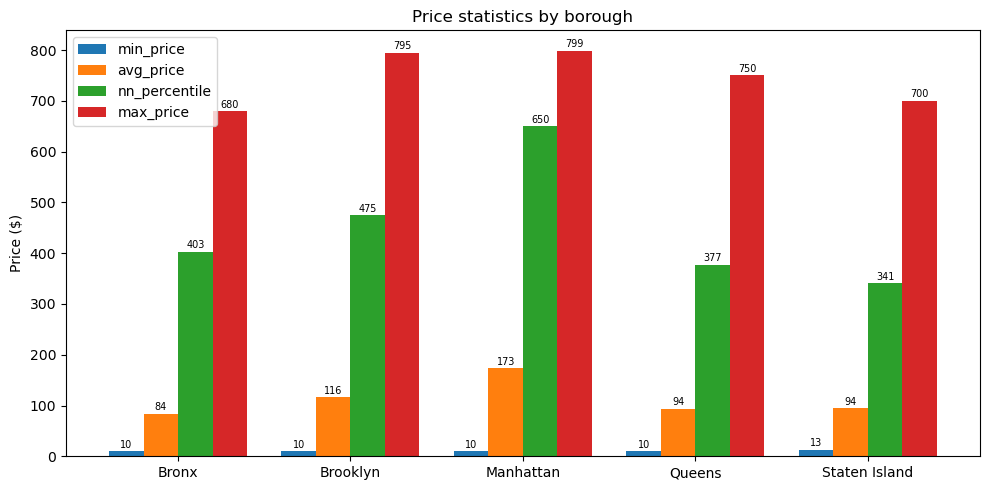

In [9]:
# 1. Neighbourhood groups (boroughs)
g = df.groupby("neighbourhood_group").price.agg(
    min_price="min", max_price="max", avg_price="mean",
    nn_percentile=lambda s: s.quantile(.99)).round(2)
print(g)

hi = g.max_price.max()
lo = g.min_price.min()
print("Highest max price:", list(g.index[g.max_price == hi]), hi)
print("Lowest min price:", list(g.index[g.min_price == lo]), lo)

In [15]:
n = (df.groupby(["neighbourhood_group", "neighbourhood"]).price
       .agg(count="count", avg_price="mean").round(2).reset_index())

MIN_N = 30                       # price rankings only use neighbourhoods with at least 30 listings
x = n[n["count"] >= MIN_N]
print(x.groupby("neighbourhood_group").size())   # how many neighbourhoods qualify per borough


highest = x.sort_values("avg_price", ascending=False).groupby("neighbourhood_group").head(3)
lowest  = x.sort_values("avg_price").groupby("neighbourhood_group").head(3)
most    = n.sort_values("count", ascending=False).groupby("neighbourhood_group").head(3)

print("HIGHEST average price");  print(highest.sort_values(["neighbourhood_group", "avg_price"], ascending=[True, False]).to_string(index=False))
print("LOWEST average price");   print(lowest.sort_values(["neighbourhood_group", "avg_price"]).to_string(index=False))
print("MOST listings");          print(most.sort_values(["neighbourhood_group", "count"], ascending=[True, False]).to_string(index=False))

neighbourhood_group
Bronx            12
Brooklyn         39
Manhattan        31
Queens           31
Staten Island     2
dtype: int64
HIGHEST average price
neighbourhood_group     neighbourhood  count  avg_price
              Bronx    Williamsbridge     40      96.75
              Bronx          Longwood     62      91.92
              Bronx        Mott Haven     60      88.92
           Brooklyn             DUMBO     36     196.31
           Brooklyn       Cobble Hill     97     187.95
           Brooklyn      Vinegar Hill     34     187.18
          Manhattan           Tribeca    156     295.65
          Manhattan              NoHo     77     276.25
          Manhattan Flatiron District     74     258.16
             Queens           Arverne     76     154.30
             Queens    Rockaway Beach     56     132.18
             Queens  Long Island City    533     121.70
      Staten Island        St. George     47      99.38
      Staten Island     Tompkinsville     42      76.19
LOWES

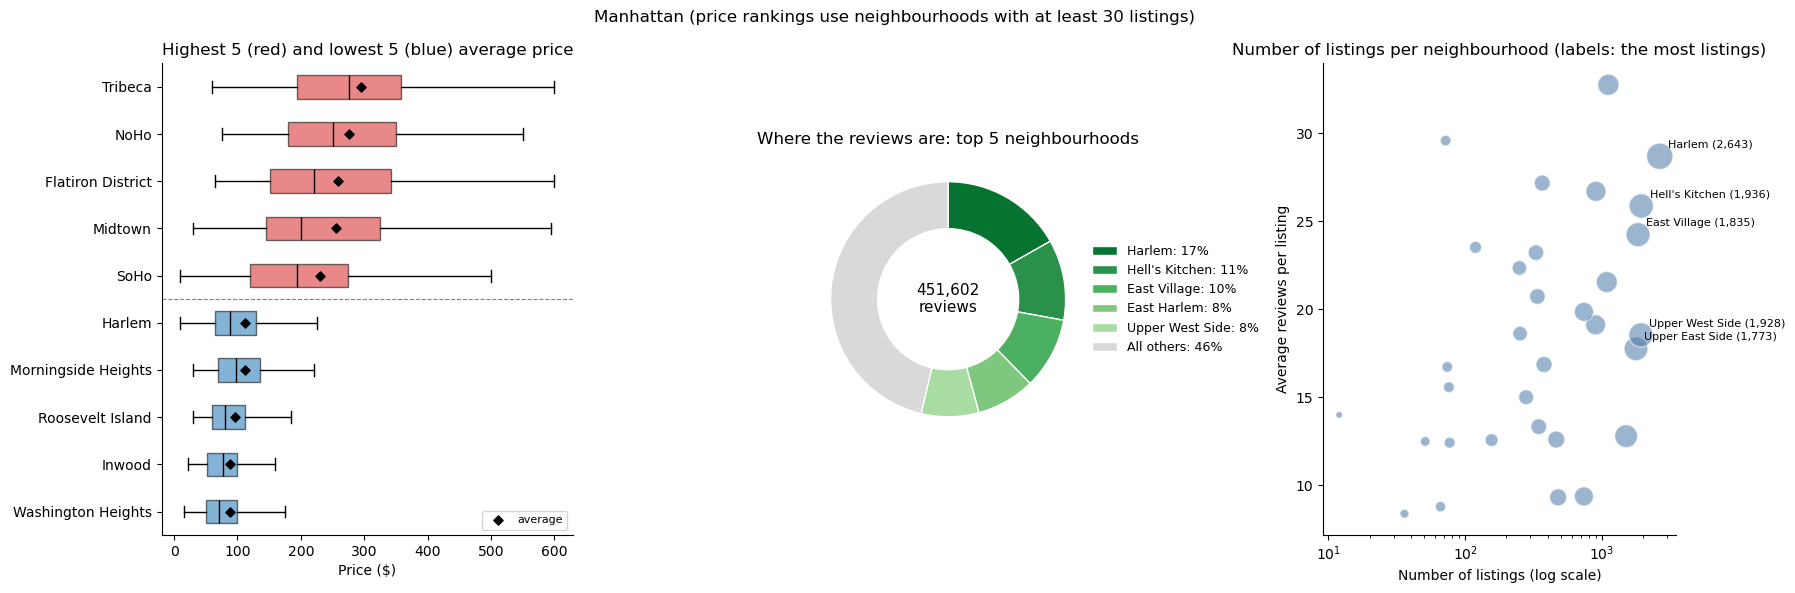

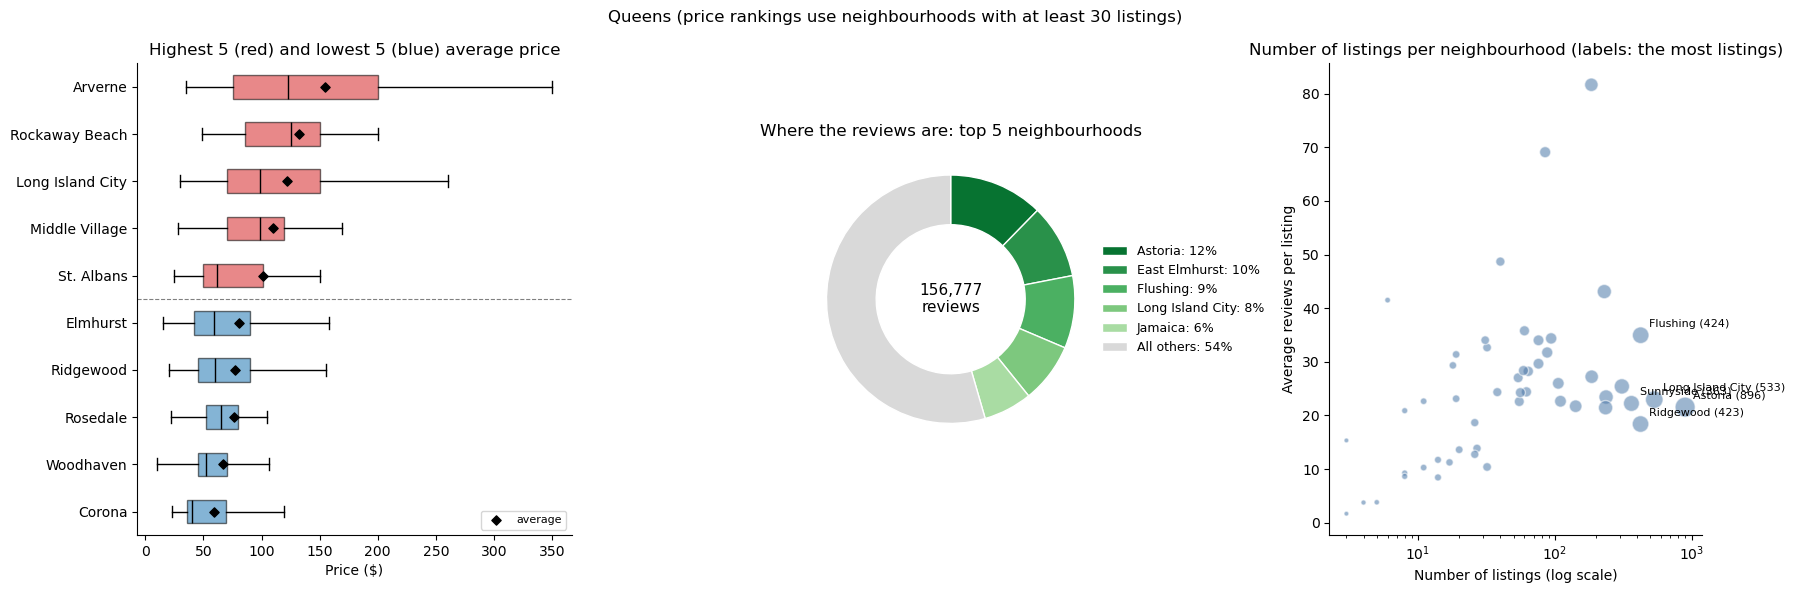

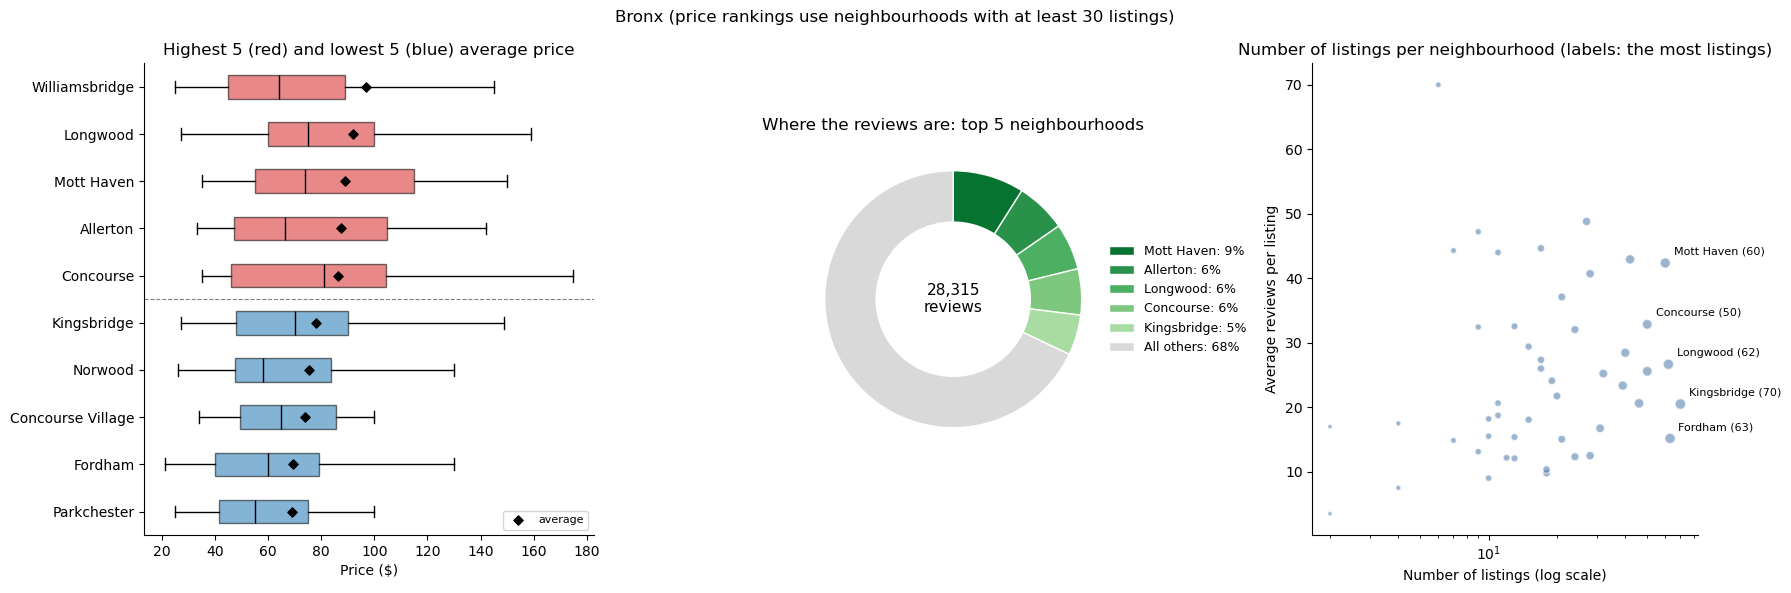

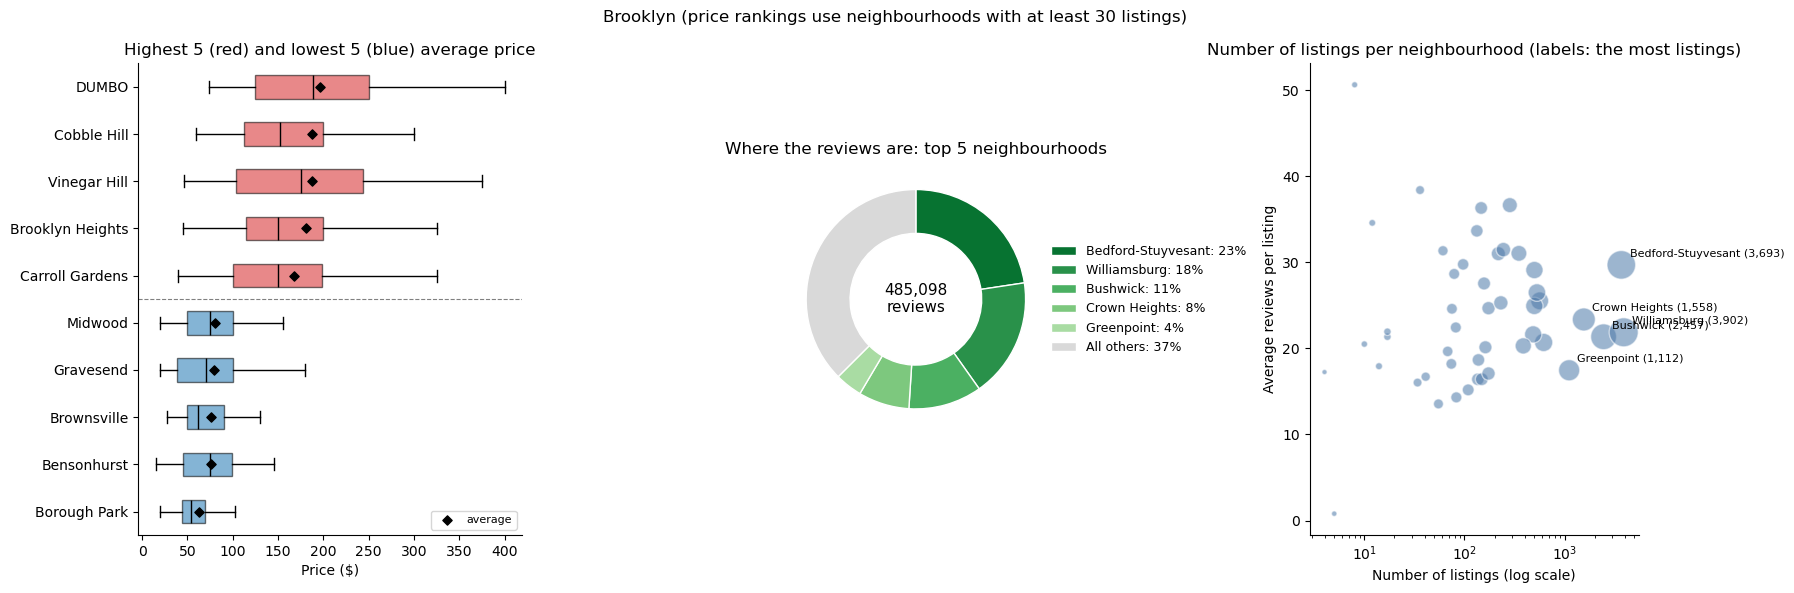

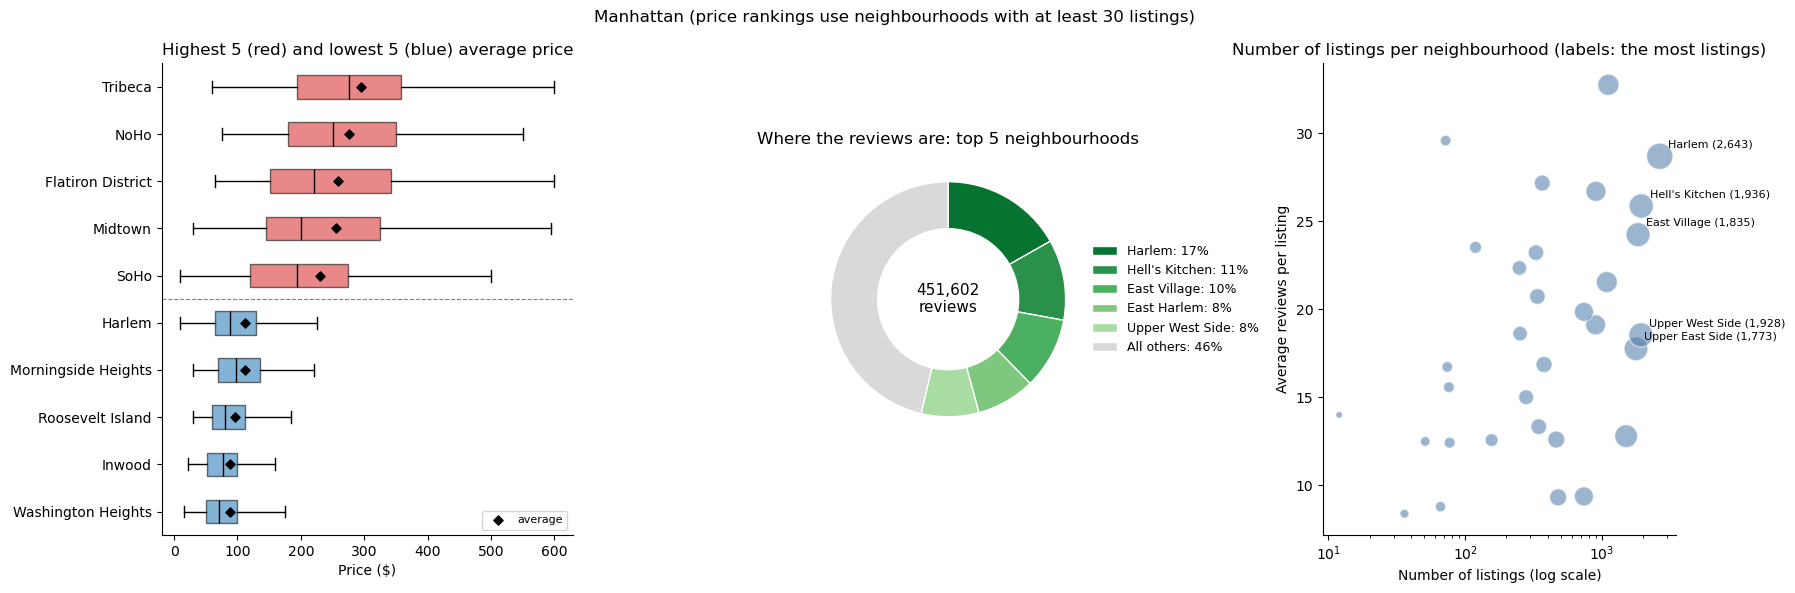

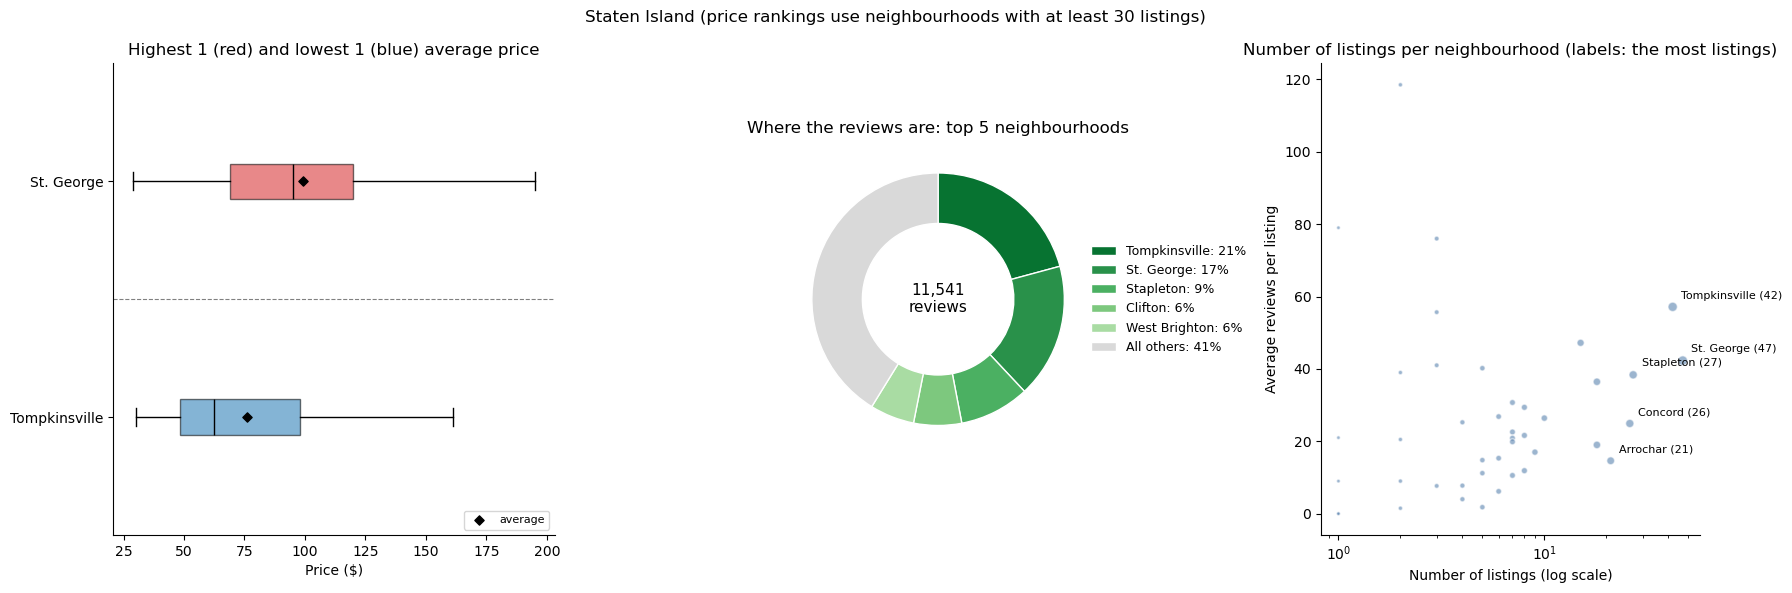

In [30]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

n = (df.groupby(["neighbourhood_group", "neighbourhood"])
       .agg(count=("price", "count"), avg_price=("price", "mean"),
            total_reviews=("number_of_reviews", "sum"), avg_reviews=("number_of_reviews", "mean"))
       .round(2).reset_index())

def borough_view(borough, top_n=5, min_listings=30):
    b = n[n.neighbourhood_group == borough]
    ranked = b[b["count"] >= min_listings].sort_values("avg_price", ascending=False)
    k = min(top_n, len(ranked) // 2)
    hi, lo = ranked.head(k).iloc[::-1], ranked.tail(k).iloc[::-1]
    sel_df = pd.concat([lo, hi]); sel = sel_df.neighbourhood.tolist()
    colors = ["#1f77b4"] * len(lo) + ["#d62728"] * len(hi)
    d = df[df.neighbourhood_group == borough]
    fig, ax = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={"width_ratios": [1.4, 1, 1.2]})

    # 1) price: highest (red) and lowest (blue) average price
    bp = ax[0].boxplot([d[d.neighbourhood == s].price for s in sel], vert=False, showfliers=False,
                       patch_artist=True, medianprops=dict(color="black"))
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(.55)
    ax[0].scatter(sel_df.avg_price, range(1, len(sel) + 1), color="black", marker="D", s=22, zorder=3, label="average")
    ax[0].set_yticks(range(1, len(sel) + 1)); ax[0].set_yticklabels(sel)
    ax[0].axhline(len(lo) + .5, color="gray", linestyle="--", linewidth=.8)
    ax[0].set_xlabel("Price ($)")
    ax[0].set_title(f"Highest {k} (red) and lowest {k} (blue) average price")
    ax[0].legend(loc="lower right", fontsize=8)

    # 2) reviews: donut, each top neighbourhood's share of the borough's reviews
    r = b.nlargest(top_n, "total_reviews")
    parts = r.total_reviews.tolist() + [b.total_reviews.sum() - r.total_reviews.sum()]
    labels = r.neighbourhood.tolist() + ["All others"]
    cols = plt.cm.Greens(np.linspace(.85, .35, top_n)).tolist() + [(.85, .85, .85, 1)]
    w, _ = ax[1].pie(parts, colors=cols, startangle=90, counterclock=False,
                     wedgeprops=dict(width=.4, edgecolor="white"))
    total = sum(parts)
    ax[1].legend(w, [f"{l}: {p / total:.0%}" for l, p in zip(labels, parts)],
                 loc="center left", bbox_to_anchor=(0.95, .5), fontsize=9, frameon=False)
    ax[1].text(0, 0, f"{total:,.0f}\nreviews", ha="center", va="center", fontsize=11)
    ax[1].set_title(f"Where the reviews are: top {top_n} neighbourhoods")

    # 3) number of listings: each dot is a neighbourhood
    ax[2].scatter(b["count"], b["avg_reviews"], s=np.sqrt(b["count"]) * 7, alpha=.55, color="#4c78a8", edgecolor="white")
    for _, row in b.nlargest(top_n, "count").iterrows():
        ax[2].annotate(f"{row.neighbourhood} ({row['count']:,})", (row["count"], row.avg_reviews),
                       xytext=(6, 6), textcoords="offset points", fontsize=8)
    ax[2].set_xscale("log"); ax[2].set_xlabel("Number of listings (log scale)"); ax[2].set_ylabel("Average reviews per listing")
    ax[2].set_title("Number of listings per neighbourhood (labels: the most listings)")
    for a in (ax[0], ax[2]): a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{borough} (price rankings use neighbourhoods with at least {min_listings} listings)", fontsize=12)
    plt.tight_layout(); plt.show()

borough_view("Manhattan", top_n=5)
borough_view("Queens", top_n=5)
borough_view("Bronx", top_n=5)
borough_view("Brooklyn", top_n=5)
borough_view("Manhattan", top_n=5)
borough_view("Staten Island", top_n=5)

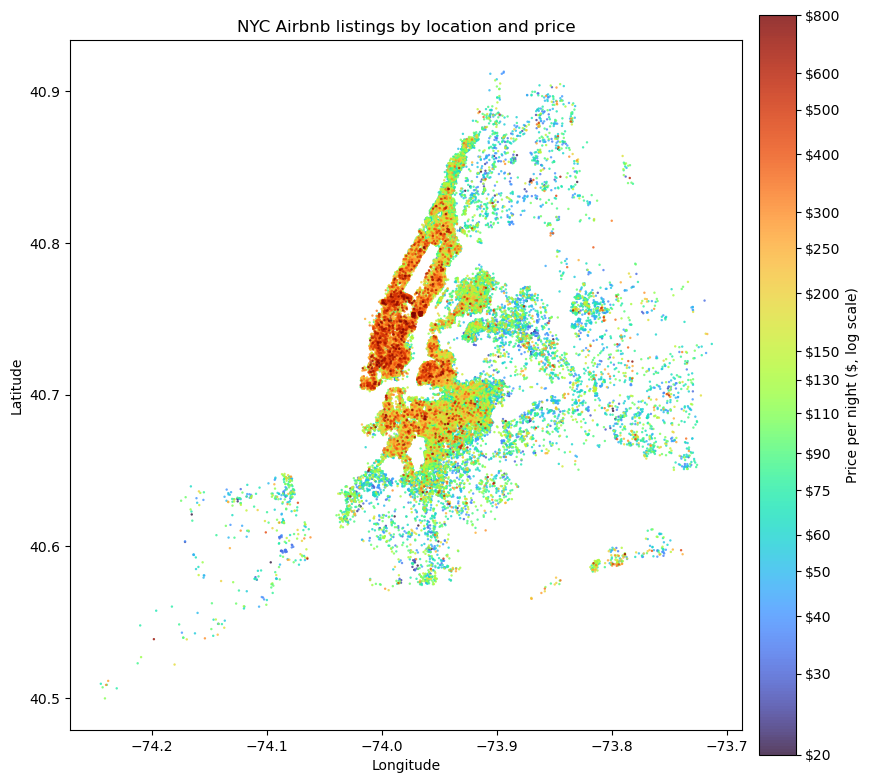

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedFormatter

df = df.sort_values("price")        # draw expensive listings last so they stay visible

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(df.longitude, df.latitude, c=df.price, s=3, cmap="turbo",
                norm=LogNorm(vmin=20, vmax=800), alpha=.8, linewidths=0)

ticks = [20, 30, 40, 50, 60, 75, 90, 110, 130, 150, 200, 250, 300, 400, 500, 600, 800]
cb = fig.colorbar(sc, ax=ax, shrink=.85, pad=.02, label="Price per night ($, log scale)")
cb.set_ticks(ticks)
cb.ax.yaxis.set_major_formatter(FixedFormatter([f"${t}" for t in ticks]))
cb.ax.minorticks_off()

ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("NYC Airbnb listings by location and price")
ax.set_aspect(1 / np.cos(np.radians(40.7)))      # keeps the map's shape correct
plt.tight_layout(); plt.show()